[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L4/BA_L4_cross_coin/BA_L4_cross_coin.ipynb)

# BA_L4_cross_coin: GARCH(1,1)-t persistence and tail thickness across assets

*Quantlet of Lecture 4, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

GARCH(1,1) with Student-t errors for 11 crypto assets, the S&P 500 and gold, daily log returns 2018 to 18 September 2026: the persistence alpha + beta and the degrees of freedom nu of each asset.

In [1]:
# packages that are not preinstalled on Colab
import importlib, subprocess, sys
for pkg in ['arch']:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)

In [2]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [3]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [4]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

**Model.** $r_t = \mu + \varepsilon_t$, $\varepsilon_t = \sigma_t z_t$, with the GARCH(1,1) recursion of Bollerslev (1986)
$$ \sigma_t^2 = \omega + \alpha\,\varepsilon_{t-1}^2 + \beta\,\sigma_{t-1}^2 , $$
and $z_t$ i.i.d. (independent and identically distributed) Student-t with $\nu$ degrees of freedom, rescaled to variance 1 (GARCH-t).
$\alpha + \beta$ is the persistence; the parameters are estimated by maximum likelihood.

**Data.** Daily closes (EODHD) of Bitcoin, Ethereum, XRP, BNB, Litecoin, Cardano, Dogecoin, Stellar, Tron, Bitcoin Cash, Chainlink, the S&P 500 and gold; log returns in per cent, 1 January 2018 – 18 September 2026 (S&P 500 and gold: Monday–Friday closes, repeated closes removed).

**How to read.** Left: $\hat\alpha + \hat\beta$, with the bound 1 dashed. Right: $\hat\nu$; below 4 (dashed) the fourth moment of the shocks is infinite.

In [5]:
from scipy import stats
from arch import arch_model

END = '2026-09-18'                      # last day of the estimation sample
ASSETS = {'Bitcoin': ('BTC-USD.CC', 365, BTC), 'Ethereum': ('ETH-USD.CC', 365, ETH),
          'S&P 500': ('GSPC.INDX', 252, BLUE), 'Gold': ('XAUUSD.FOREX', 252, GOLD)}


def closes(sym, end):
    # daily closes; S&P 500 and gold: Monday-Friday only, repeated closes removed
    p = daily(sym, end)
    if sym.endswith(('.INDX', '.FOREX')):
        p = p[p.index.dayofweek < 5]
        p = p[p.diff().ne(0)]
    return p


def log_returns(sym, start='2018-01-01'):
    # daily log returns in %, from `start` to END
    p = closes(sym, END)
    return (100 * np.log(p).diff()).dropna().loc[start:]

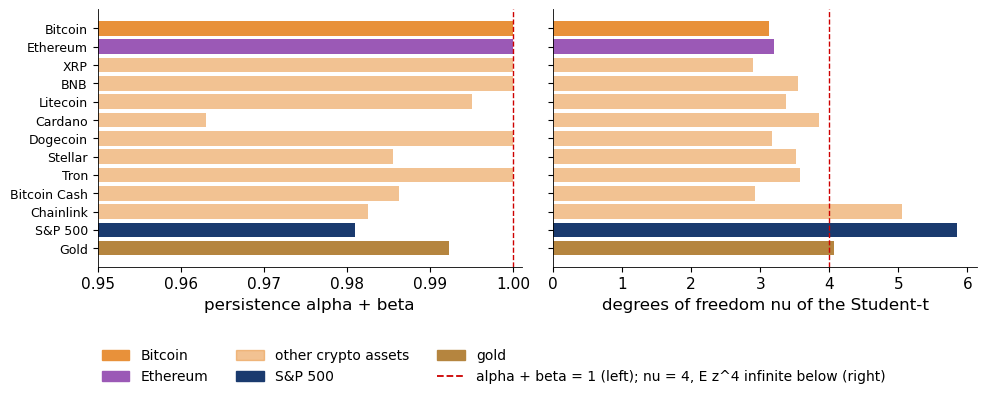

In [6]:
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
COINS = [('Bitcoin', 'BTC-USD.CC'), ('Ethereum', 'ETH-USD.CC'), ('XRP', 'XRP-USD.CC'), ('BNB', 'BNB-USD.CC'), ('Litecoin', 'LTC-USD.CC'),
         ('Cardano', 'ADA-USD.CC'), ('Dogecoin', 'DOGE-USD.CC'), ('Stellar', 'XLM-USD.CC'), ('Tron', 'TRX-USD.CC'),
         ('Bitcoin Cash', 'BCH-USD.CC'), ('Chainlink', 'LINK-USD.CC'), ('S&P 500', 'GSPC.INDX'), ('Gold', 'XAUUSD.FOREX')]
cc = {}
for nm, sym in COINS:
    g_ = arch_model(log_returns(sym), mean='Constant', vol='GARCH', p=1, q=1, dist='t').fit(disp='off')
    cc[nm] = {'alpha': g_.params['alpha[1]'], 'beta': g_.params['beta[1]'], 'alpha + beta': g_.params['alpha[1]'] + g_.params['beta[1]'],
              'nu': g_.params['nu'], 'se nu': g_.std_err['nu']}
CC = pd.DataFrame(cc).T
fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
yy = np.arange(len(CC))[::-1]
for i_, a_ in enumerate(CC.index):
    col_ = {'Bitcoin': BTC, 'Ethereum': ETH, 'S&P 500': BLUE, 'Gold': GOLD}.get(a_, BTC)
    al_ = 1 if a_ in ('Bitcoin', 'Ethereum', 'S&P 500', 'Gold') else 0.55
    ax[0].barh(yy[i_], CC.loc[a_, 'alpha + beta'], color=col_, alpha=al_)
    ax[1].barh(yy[i_], CC.loc[a_, 'nu'], color=col_, alpha=al_)
ax[0].set_xlim(0.95, 1.001); ax[0].set_xlabel('persistence alpha + beta'); ax[0].axvline(1, color=RED, ls='--', lw=1)
ax[1].axvline(4, color=RED, ls='--', lw=1); ax[1].set_xlabel('degrees of freedom nu of the Student-t')
ax[0].set_yticks(yy); ax[0].set_yticklabels(CC.index, fontsize=9)
hd = [Patch(color=BTC, label='Bitcoin'), Patch(color=ETH, label='Ethereum'), Patch(color=BTC, alpha=0.55, label='other crypto assets'),
      Patch(color=BLUE, label='S&P 500'), Patch(color=GOLD, label='gold'),
      Line2D([], [], color=RED, ls='--', label='alpha + beta = 1 (left); nu = 4, E z^4 infinite below (right)')]
fig.legend(handles=hd, loc='lower center', ncol=3, frameon=False); fig.tight_layout(rect=(0, 0.16, 1, 1))
save_fig(fig, 'ba_l4_cross_coin')

**Key numbers** (as on the slide).

In [7]:
cr = CC.drop(['S&P 500', 'Gold'])
print(f"crypto assets at the bound alpha + beta = 1: {list(cr.index[cr['alpha + beta'] > 0.9999])}")
print(f"crypto nu from {cr['nu'].min():.2f} ({cr['nu'].idxmin()}) to {cr['nu'].max():.2f} ({cr['nu'].idxmax()}); below 4: {int((cr['nu'] < 4).sum())} of {len(cr)}")
CC.round(3)

crypto assets at the bound alpha + beta = 1: ['Bitcoin', 'Ethereum', 'XRP', 'BNB', 'Dogecoin', 'Tron']
crypto nu from 2.90 (XRP) to 5.05 (Chainlink); below 4: 10 of 11


,alpha,beta,alpha + beta,nu,se nu
Bitcoin,0.076,0.924,1.000,3.126,0.153
Ethereum,0.117,0.883,1.000,3.193,0.196
XRP,0.235,0.765,1.000,2.900,0.141
BNB,0.123,0.877,1.000,3.543,0.220
Litecoin,0.088,0.907,0.995,3.369,0.208
Cardano,0.167,0.796,0.963,3.848,0.267
Dogecoin,0.266,0.734,1.000,3.166,0.156
Stellar,0.168,0.817,0.985,3.513,0.218
Tron,0.146,0.854,1.000,3.570,0.189
Bitcoin Cash,0.091,0.895,0.986,2.920,0.159
